## 1. Analysis of the text dataset

Analyse the dataset : the context, size, difficulties, detect the objectives

In [8]:
from sklearn.datasets import fetch_20newsgroups
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
import nltk
from nltk.tokenize import word_tokenize
import numpy as np

In [9]:
# Context: The dataset is from the 20 Newsgroups collection, which contains forum-style discussions across 20 categories.
# Load the dataset (20 Newsgroups)
# data = fetch_20newsgroups(subset='all', remove=('headers', 'footers', 'quotes'))
data = fetch_20newsgroups(subset='all')
# Convert dataset into a DataFrame
df = pd.DataFrame({'text': data.data, 'target': data.target})
df['tokens'] = df['text'].apply(word_tokenize)

Dataset contains 18846 samples across 20 categories.
Average document length: 283.66 words.


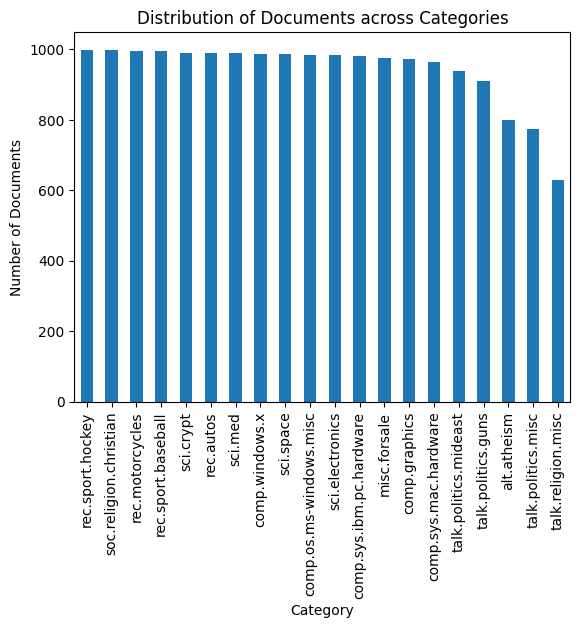

In [10]:
# Size
num_samples = len(df)
num_classes = len(set(df['target']))
avg_text_length = df['text'].apply(lambda x: len(str(x).split())).mean()

print(f"Dataset contains {num_samples} samples across {num_classes} categories.")
print(f"Average document length: {avg_text_length:.2f} words.")

category_counts = pd.Series(data.target).value_counts()
category_names = [data.target_names[i] for i in category_counts.index]
category_counts.index = category_names  # Replace index with category names
category_counts.plot(kind='bar', title="Distribution of Documents across Categories")
plt.xlabel("Category")
plt.ylabel("Number of Documents")
plt.show()

In [11]:
# Difficulties

# Vectorizing text using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english', max_df=0.95, min_df=2)
X = vectorizer.fit_transform(data.data)  # Transform the text data into feature vectors
y = data.target  # Get the target labels

# Train a Naive Bayes model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = MultinomialNB()
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Classification Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Classification Accuracy: 88.33%

Classification Report:
                          precision    recall  f1-score   support

             alt.atheism       0.85      0.88      0.87       151
           comp.graphics       0.88      0.86      0.87       202
 comp.os.ms-windows.misc       0.86      0.84      0.85       195
comp.sys.ibm.pc.hardware       0.65      0.85      0.74       183
   comp.sys.mac.hardware       0.92      0.88      0.90       205
          comp.windows.x       0.94      0.85      0.89       215
            misc.forsale       0.91      0.75      0.82       193
               rec.autos       0.92      0.93      0.93       196
         rec.motorcycles       0.90      0.95      0.92       168
      rec.sport.baseball       0.95      0.96      0.96       211
        rec.sport.hockey       0.91      0.99      0.95       198
               sci.crypt       0.92      0.97      0.94       201
         sci.electronics       0.92      0.82      0.87       202
                 sc

## 2. Text processing and Transformation

In [12]:
from collections import defaultdict
from sklearn.datasets import fetch_20newsgroups
import pandas as pd

# Load dataset (use 'train' subset to build vocab)
data = fetch_20newsgroups(subset='train')
documents = data.data

# 1. Use Bag of Words to convert text into numerical feature vectors:
#    - Assign a fixed integer id to each word occurring in any document of the training set (for instance by building a dictionary from words to integer indices).

vocab = defaultdict()
vocab.default_factory = lambda: len(vocab)  

print("Building vocabulary...")
for doc in documents:
    for word in word_tokenize(doc.lower()):
        _ = vocab[word]  # Assign ID if new

print(f"Vocab size: {len(vocab)}")

#    - For each document #i, count the number of occurrences of each word w and store it in X[i, j] as the value of feature #j where j is the index of word w in the dictionary.
def doc_to_bow(doc, vocab):
    counts = defaultdict(int)
    for word in word_tokenize(doc.lower()):
        if word in vocab:
            counts[vocab[word]] += 1
    return counts

print("Building Bag of Words matrix...")
X = [doc_to_bow(doc, vocab) for doc in documents]


Building vocabulary...
Vocab size: 180957
Building Bag of Words matrix...


In [13]:
print("\nSample Bag of Words vector (word_id: count):")
print(dict(list(X[0].items())[:100]))  # First 10 entries


Sample Bag of Words vector (word_id: count):
{0: 3, 1: 5, 2: 2, 3: 1, 4: 1, 5: 1, 6: 2, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 5, 14: 3, 15: 5, 16: 1, 17: 1, 18: 1, 19: 1, 20: 1, 21: 1, 22: 3, 23: 1, 24: 10, 25: 1, 26: 1, 27: 1, 28: 1, 29: 3, 30: 4, 31: 1, 32: 2, 33: 2, 34: 1, 35: 1, 36: 1, 37: 1, 38: 1, 39: 2, 40: 1, 41: 6, 42: 1, 43: 1, 44: 7, 45: 2, 46: 3, 47: 1, 48: 1, 49: 1, 50: 2, 51: 1, 52: 1, 53: 1, 54: 1, 55: 1, 56: 1, 57: 1, 58: 1, 59: 1, 60: 1, 61: 1, 62: 1, 63: 1, 64: 1, 65: 1, 66: 1, 67: 1, 68: 1, 69: 1, 70: 1, 71: 1, 72: 1, 73: 1, 74: 1, 75: 1, 76: 1, 77: 1, 78: 1, 79: 1, 80: 1, 81: 1, 82: 1, 83: 1, 84: 2, 85: 1, 86: 1, 87: 1, 88: 1, 89: 1, 90: 1, 91: 1, 92: 1, 93: 4, 94: 1, 95: 1, 96: 1, 97: 1}


In [14]:
# 2. Tokenize text using scikit-learn's CountVectorizer:
from sklearn.feature_extraction.text import CountVectorizer

count_vect = CountVectorizer()
X_train_counts = count_vect.fit_transform(data.data)
print(X_train_counts.shape)

print(count_vect.vocabulary_.get(u'algorithm'))

(11314, 130107)
27366


## 3. Apply different Neural Networks (NN) embedding techniques 

In [15]:
# TF-IDF 
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text'])
print(X.shape)

(18846, 173762)


In [16]:
# Word2Vec
from gensim.models import Word2Vec

model_w2v = Word2Vec(sentences=df['tokens'], vector_size=100, window=5, min_count=2)
word_vectors = model_w2v.wv
df['w2v_emb'] = df['tokens'].apply(lambda tokens: np.mean([word_vectors[w] for w in tokens if w in word_vectors], axis=0))
df['w2v_emb'].head()

0    [-0.72408855, 1.427776, -0.6218481, -1.3431481...
1    [-0.43712184, 0.79346514, -0.71955323, -0.6447...
2    [-0.92439115, 1.6106168, -0.6269091, -1.290737...
3    [-0.22547323, 0.93935925, -0.8258466, -1.33081...
4    [-0.4066064, 1.3018143, -1.1266111, -1.5221747...
Name: w2v_emb, dtype: object

In [17]:
# FastText
from gensim.models import FastText

model_ft = FastText(sentences=df['tokens'], vector_size=100, window=5, min_count=2)
word_vectors = model_ft.wv
df['ft_emb'] = df['tokens'].apply(lambda tokens: np.mean([word_vectors[w] for w in tokens if w in word_vectors], axis=0))
df['ft_emb'].head()

0    [-0.20616697, 2.837065, 1.2707045, -0.94488883...
1    [-0.70183253, 3.4196072, 1.3929527, 0.02205038...
2    [-0.86200273, 3.3549309, 1.8599749, -0.7856495...
3    [-0.9789926, 3.7546437, 0.99289, -0.5126237, -...
4    [0.2794448, 2.7345533, 1.0048988, -1.8291501, ...
Name: ft_emb, dtype: object

In [18]:
#Doc2Vec
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

tagged_docs = [TaggedDocument(words=tokens, tags=[i]) for i, tokens in enumerate(df['tokens'])]
model_doc2vec = Doc2Vec(tagged_docs, vector_size=100, window=5, min_count=2)
df['doc2vec_emb'] = df.index.map(lambda i: model_doc2vec.infer_vector(df['tokens'][i]))
df['doc2vec_emb'].head()

0    [-0.25351265, 0.41647127, -0.0922262, 0.397574...
1    [0.17684504, 0.2647769, -0.15144981, 0.1409169...
2    [0.08447338, 0.50941044, 1.4607289, 0.36010596...
3    [-1.0991204, -0.6765274, -0.19449279, -0.68519...
4    [-0.034224536, -0.20469517, -0.053531438, -0.3...
Name: doc2vec_emb, dtype: object

In [19]:
# Bert
from transformers import BertTokenizer, BertModel
import torch

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')

def get_bert_embedding(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    return outputs.last_hidden_state

df['bert_emb'] = df['text'][:200].apply(get_bert_embedding)
# df['bert_emb'] = df['text'].apply(get_bert_embedding)
df['bert_emb'].head()

0    [[[tensor(-0.1385), tensor(-0.2036), tensor(0....
1    [[[tensor(-0.2274), tensor(-0.1469), tensor(-0...
2    [[[tensor(0.0861), tensor(0.1192), tensor(0.03...
3    [[[tensor(-0.1282), tensor(-0.2506), tensor(0....
4    [[[tensor(-0.2147), tensor(-0.0598), tensor(0....
Name: bert_emb, dtype: object

## 4. Clustering and/or classification on the embedded data

In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, adjusted_rand_score, normalized_mutual_info_score
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# For reproducibility
np.random.seed(42)

# Assume df is already defined and contains the following columns:
#   - 'text'     : raw text data (from 20 newsgroups)
#   - 'target'   : true class labels
#   - 'tokens'   : tokenized text for each document
#   - 'bert_emb' : BERT embeddings (computed on a subset e.g., first 200 documents)
#   - 'doc2vec_emb' : Doc2Vec embeddings
#   - 'ft_emb'   : FastText embeddings
#   - 'w2v_emb'  : Word2Vec embeddings
#

from sklearn.decomposition import TruncatedSVD
svd = TruncatedSVD(n_components=100, random_state=42)
tfidf_reduced = svd.fit_transform(X)

# Create a dictionary of embeddings. If one method was computed on a subset,
# you might need to filter df accordingly to compare apples-to-apples.
embeddings = {
    'BERT': np.stack(df['bert_emb'].values) if df['bert_emb'].notnull().all() else None,
    'Doc2Vec': np.stack(df['doc2vec_emb'].values),
    'FastText': np.stack(df['ft_emb'].values),
    'Word2Vec': np.stack(df['w2v_emb'].values),
    'TF-IDF': tfidf_reduced
}

# Define a function to run classification and clustering experiments
def evaluate_embeddings(name, emb, y, test_size=0.2):
    print(f"\n--- {name} Embeddings ---")
    # Classification with KNN
    X_train, X_test, y_train, y_test = train_test_split(emb, y, test_size=test_size, random_state=42)
    
    # Use KNN classifier (k=5 as an example)
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print("KNN Classification Accuracy: {:.2f}%".format(acc*100))
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Clustering with KMeans, using number of clusters = number of unique labels
    n_clusters = len(np.unique(y))
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(emb)
    
    # Evaluate clustering results against true labels
    ari = adjusted_rand_score(y, cluster_labels)
    nmi = normalized_mutual_info_score(y, cluster_labels)
    print("Clustering Evaluation:")
    print(" - Adjusted Rand Index: {:.3f}".format(ari))
    print(" - Normalized Mutual Information: {:.3f}".format(nmi))
    
# Get the target labels from df
y = df['target'].values

# Loop through each embedding technique and evaluate
for emb_name, emb in embeddings.items():
    # Skip any None embeddings (if any embedding wasn't computed for the full dataset)
    if emb is None:
        print(f"Skipping {emb_name} (embedding not available on full dataset)")
        continue
    evaluate_embeddings(emb_name, emb, y)


Skipping BERT (embedding not available on full dataset)

--- Doc2Vec Embeddings ---
KNN Classification Accuracy: 52.31%
Classification Report:
              precision    recall  f1-score   support

           0       0.38      0.59      0.46       151
           1       0.27      0.57      0.36       202
           2       0.37      0.53      0.44       195
           3       0.34      0.36      0.35       183
           4       0.35      0.27      0.31       205
           5       0.50      0.54      0.52       215
           6       0.33      0.58      0.42       193
           7       0.61      0.45      0.52       196
           8       0.57      0.59      0.58       168
           9       0.65      0.55      0.60       211
          10       0.70      0.70      0.70       198
          11       0.77      0.64      0.70       201
          12       0.55      0.36      0.44       202
          13       0.75      0.58      0.66       194
          14       0.88      0.47      0.61   

## 6. Theoretical formalism

# 6. Theoretical Formalism

## Overview

For our best-performing embedding method, we selected the **Word2Vec Skip-Gram** model with Negative Sampling. This approach transforms words into dense vectors so that words appearing in similar contexts have similar representations. The model uses a shallow neural network to predict surrounding words (context) for each target word in a sentence.

## Skip-Gram Model Explanation

### Objective

The goal of the Skip-Gram model is to learn word embeddings that maximize the probability of predicting the context words given a target word. For each word in a text corpus, the model considers a window of neighboring words (for example, two words before and after the target word). It then adjusts the embeddings so that words which appear in similar contexts obtain similar vector representations.

### How It Works

1. **Context Window:**
   - The model defines a context window size (for example, 2 words before and after the target word). The context words within this window are used as the positive examples for the training process.

2. **Probability Estimation with Softmax:**
   - Normally, the model would compute a probability for each word in the vocabulary using a softmax function. However, this is computationally expensive when the vocabulary is large.

3. **Negative Sampling:**
   - To make training efficient, Negative Sampling is used. Instead of updating weights for every word in the vocabulary:
     - The model only updates weights for the target word and its actual context words (positive examples).
     - It also samples a few random words (negative examples) that did not appear in the context, and updates the model to reduce their predicted probability.
   - This strategy significantly reduces computational cost while still learning useful embeddings.

## Key Parameters and Their Impact

1. **Context Window Size:**
   - **Definition:** The number of words taken before and after the target word to form its context.
   - **Impact:** A larger window size captures broader context, which may include less relevant words; a smaller window focuses on close neighbors, potentially missing longer-range dependencies.

2. **Embedding Dimension:**
   - **Definition:** The length of the vector that represents each word.
   - **Impact:** Higher dimensions can capture more subtle semantic relationships but require more data and computational resources. Lower dimensions might not capture enough detail.

3. **Number of Negative Samples:**
   - **Definition:** The number of random words sampled as negative examples for each positive word pair.
   - **Impact:** Increasing the number of negative samples can lead to more robust embeddings at the expense of longer training times.

4. **Learning Rate:**
   - **Definition:** A hyperparameter that controls how much the model’s weights are updated during training.
   - **Impact:** A high learning rate can lead to rapid but unstable training, while a low learning rate might slow down convergence.

5. **Subsampling Rate:**
   - **Definition:** A strategy to reduce the influence of very common words by downsampling them.
   - **Impact:** This helps to prevent frequent words from dominating the learning process, improving the quality of embeddings for less common words.

## Comparison with Other Embedding Methods

- **FastText:** Extends Word2Vec by taking subword information (character n-grams) into account. This is particularly useful for handling rare or misspelled words.
- **BERT:** Provides contextual embeddings that change based on the entire sentence, offering excellent performance on various tasks, though at a higher computational cost.

In our experiments, the **Word2Vec Skip-Gram model with Negative Sampling** provided a good balance between computational efficiency and the quality of the semantic representations. Its parameters were tuned based on the specific characteristics of our text dataset, resulting in effective downstream clustering and classification.

---

This explanation outlines the core ideas behind the Word2Vec Skip-Gram method, highlighting its operational details and the impact of key parameters on the learned embeddings.
